# Computer Vision Ödevi – Fashion-MNIST ile Kıyafet Sınıflandırma (CNN, PyTorch)

**Öğrenci:** Zeynep Tuğba KURT
**Numara:** 24120205005

Bu notebook'ta Fashion-MNIST veri seti ile 10 sınıflı bir görüntü sınıflandırma modeli (CNN) eğitilmiş,
test edilmiş ve telefonla çektiğim 5 fotoğraf üzerinde denenmiştir.

Notebook ödevdeki maddelere göre bölümlere ayrılmıştır:
1. Kütüphaneler ve ayarlar
2. Veri seti (train / validation / test)
3. Model (CNN)
4. Hiperparametreler, loss ve optimizer
5. Eğitim
6. Performans değerlendirmesi (Accuracy, Precision, Recall, F1, eğitim ve tahmin süresi)
7. Telefon fotoğraflarıyla test

## 1. Kütüphaneler ve ayarlar

In [1]:
import os, time, json, glob, platform

import numpy as np
import matplotlib.pyplot as plt
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

# Sonuçların tekrarlanabilir olması için seed
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# GPU varsa kullan (Mac'te Apple Silicon için 'mps', NVIDIA için 'cuda')
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("PyTorch sürümü:", torch.__version__)
print("Kullanılan cihaz:", device)

os.makedirs("outputs", exist_ok=True)

PyTorch sürümü: 2.15.0
Kullanılan cihaz: mps


## 2. Veri Seti

**Fashion-MNIST** (Zalando): 10 sınıf, 28x28 gri tonlu, toplam 70.000 görüntü.
URL: https://github.com/zalandoresearch/fashion-mnist

- Resmî eğitim kümesi (60.000) → %90 **eğitim** (54.000) + %10 **doğrulama** (6.000)
- Resmî test kümesi (10.000) → **test**

Eğitim görüntülerine veri artırma uyguladım (yatay çevirme + küçük kaydırma). Doğrulama ve test kümelerine artırma uygulanmaz.

In [2]:
CLASSES = ["Tişört/Üst", "Pantolon", "Kazak", "Elbise", "Mont/Ceket",
           "Sandalet", "Gömlek", "Spor ayakkabı", "Çanta", "Bot"]

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=0, translate=(0.08, 0.08)),   # ±2 piksel kadar kaydırma
    transforms.ToTensor(),                                         # 0-255 -> 0-1
])
test_transform = transforms.ToTensor()

# İlk çalıştırmada veri seti ./data klasörüne indirilir
full_train_aug   = datasets.FashionMNIST("data", train=True,  download=True, transform=train_transform)
full_train_plain = datasets.FashionMNIST("data", train=True,  download=True, transform=test_transform)
test_set         = datasets.FashionMNIST("data", train=False, download=True, transform=test_transform)

# 60.000 -> 54.000 eğitim + 6.000 doğrulama
idx = torch.randperm(len(full_train_plain), generator=torch.Generator().manual_seed(SEED))
train_idx, val_idx = idx[:54000], idx[54000:]
train_set = Subset(full_train_aug, train_idx)
val_set   = Subset(full_train_plain, val_idx)

print("Eğitim:", len(train_set), " Doğrulama:", len(val_set), " Test:", len(test_set))

Eğitim: 54000  Doğrulama: 6000  Test: 10000


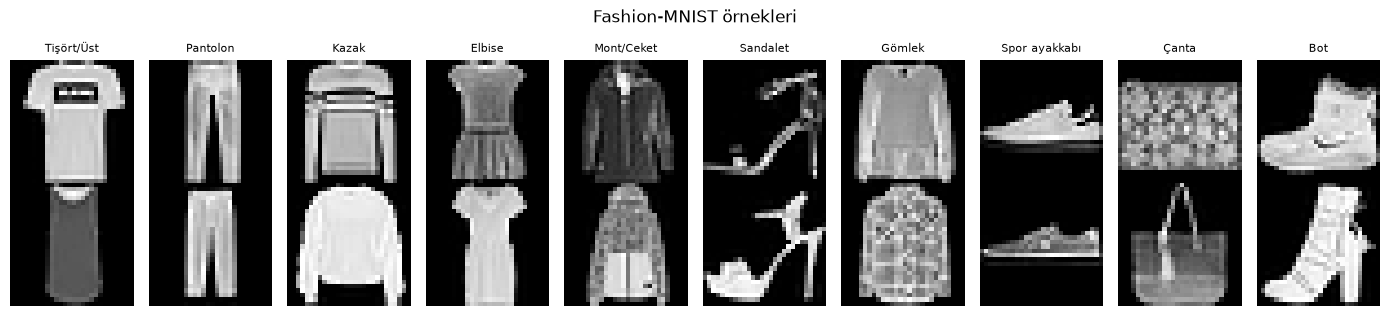

In [3]:
# Veri setinden örnek görüntüler
targets = full_train_plain.targets.numpy()
fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for c in range(10):
    ids = np.where(targets == c)[0][:2]
    for r in range(2):
        axes[r, c].imshow(full_train_plain.data[ids[r]], cmap="gray")
        axes[r, c].axis("off")
    axes[0, c].set_title(CLASSES[c], fontsize=8)
plt.suptitle("Fashion-MNIST örnekleri")
plt.tight_layout()
plt.savefig("outputs/veri_ornekleri.png", dpi=150)
plt.show()

## 3. Model (CNN)

LeNet'ten esinlenen, iki evrişim bloğu olan basit bir CNN kullandım:

| Katman | Çıkış |
|---|---|
| Conv(1→32, 3x3) + BatchNorm + ReLU + MaxPool | 32 x 14 x 14 |
| Conv(32→64, 3x3) + BatchNorm + ReLU + MaxPool | 64 x 7 x 7 |
| Flatten → Dropout(0.3) → Linear(3136→128) + ReLU | 128 |
| Dropout(0.3) → Linear(128→10) | 10 (logit) |

Softmax katmanı modele eklenmedi çünkü `CrossEntropyLoss` softmax'ı kendi içinde uyguluyor. Tahmin yaparken olasılık için `softmax` ayrıca uygulanıyor.

In [4]:
class FashionCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.pool = nn.MaxPool2d(2)
        self.dropout = nn.Dropout(0.3)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))   # 32 x 14 x 14
        x = self.pool(F.relu(self.bn2(self.conv2(x))))   # 64 x 7 x 7
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)

model = FashionCNN().to(device)
print(model)
n_params = sum(p.numel() for p in model.parameters())
print("Toplam parametre sayısı:", n_params)

FashionCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
Toplam parametre sayısı: 421834


## 4. Hiperparametreler, Loss ve Optimizer

- **Learning rate:** 0.001, her 5 epoch'ta yarıya iniyor (StepLR). Adam için standart başlangıç değeri.
- **Batch size:** 64
- **Epoch:** 15 (en iyi doğrulama doğruluğuna sahip model kaydediliyor)
- **Optimizer:** Adam. SGD'ye göre daha hızlı ve kararlı öğreniyor.
- **Weight decay (L2):** 1e-4, **Dropout:** 0.3 → aşırı öğrenmeyi azaltmak için
- **Aktivasyon:** ReLU, **çıkış:** Softmax
- **Loss:** Cross-Entropy (çok sınıflı sınıflandırma için standart)

In [5]:
LEARNING_RATE = 0.001
BATCH_SIZE = 64
EPOCHS = 15
WEIGHT_DECAY = 1e-4

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_set, batch_size=256)
test_loader  = DataLoader(test_set, batch_size=256)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)

## 5. Eğitim

In [6]:
def evaluate(model, loader):
    """Verilen kümede loss ve accuracy hesaplar."""
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += criterion(out, y).item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n


history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc, best_epoch = 0.0, 0
start = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss, correct, n = 0.0, 0, 0
    t0 = time.time()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(y)
        correct += (out.argmax(1) == y).sum().item()
        n += len(y)
    scheduler.step()

    train_loss, train_acc = running_loss / n, correct / n
    val_loss, val_acc = evaluate(model, val_loader)
    for k, v in zip(history, [train_loss, train_acc, val_loss, val_acc]):
        history[k].append(v)

    # En iyi modeli kaydet
    if val_acc > best_val_acc:
        best_val_acc, best_epoch = val_acc, epoch
        torch.save(model.state_dict(), "outputs/fashion_cnn.pth")

    print(f"Epoch {epoch:2d}/{EPOCHS} | train loss {train_loss:.4f} acc {train_acc:.4f} | "
          f"val loss {val_loss:.4f} acc {val_acc:.4f} | {time.time() - t0:.1f} sn")

training_time = time.time() - start
print(f"\nToplam eğitim süresi: {training_time:.1f} sn")
print(f"En iyi doğrulama doğruluğu: {best_val_acc:.4f} (epoch {best_epoch})")

Epoch  1/15 | train loss 0.6010 acc 0.7785 | val loss 0.3791 acc 0.8608 | 16.2 sn
Epoch  2/15 | train loss 0.4442 acc 0.8368 | val loss 0.3287 acc 0.8795 | 15.9 sn
Epoch  3/15 | train loss 0.4002 acc 0.8543 | val loss 0.2965 acc 0.8917 | 15.6 sn
Epoch  4/15 | train loss 0.3715 acc 0.8651 | val loss 0.2850 acc 0.8958 | 15.7 sn
Epoch  5/15 | train loss 0.3580 acc 0.8694 | val loss 0.2780 acc 0.8967 | 15.7 sn
Epoch  6/15 | train loss 0.3186 acc 0.8838 | val loss 0.2506 acc 0.9093 | 15.9 sn
Epoch  7/15 | train loss 0.3088 acc 0.8874 | val loss 0.2425 acc 0.9125 | 15.6 sn
Epoch  8/15 | train loss 0.3049 acc 0.8904 | val loss 0.2351 acc 0.9153 | 16.0 sn
Epoch  9/15 | train loss 0.2936 acc 0.8918 | val loss 0.2267 acc 0.9177 | 15.1 sn
Epoch 10/15 | train loss 0.2917 acc 0.8944 | val loss 0.2279 acc 0.9168 | 14.8 sn
Epoch 11/15 | train loss 0.2770 acc 0.8994 | val loss 0.2166 acc 0.9202 | 14.5 sn
Epoch 12/15 | train loss 0.2729 acc 0.8992 | val loss 0.2206 acc 0.9185 | 14.9 sn
Epoch 13/15 | tr

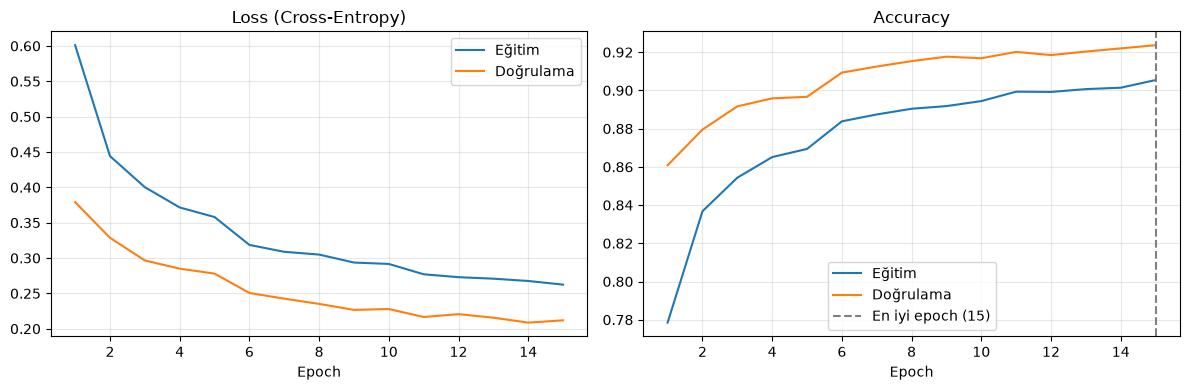

In [7]:
# Eğitim eğrileri
ep = range(1, len(history["train_loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ep, history["train_loss"], label="Eğitim")
ax[0].plot(ep, history["val_loss"], label="Doğrulama")
ax[0].set_title("Loss (Cross-Entropy)"); ax[0].set_xlabel("Epoch"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(ep, history["train_acc"], label="Eğitim")
ax[1].plot(ep, history["val_acc"], label="Doğrulama")
ax[1].axvline(best_epoch, ls="--", c="gray", label=f"En iyi epoch ({best_epoch})")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig("outputs/egitim_egrileri.png", dpi=150)
plt.show()

## 6. Performans Değerlendirmesi (Test kümesi)

En iyi model yüklenip eğitimde hiç kullanılmayan 10.000 görüntülük test kümesinde değerlendiriliyor.

In [8]:
model.load_state_dict(torch.load("outputs/fashion_cnn.pth", map_location=device))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        out = model(x.to(device))
        all_preds.append(out.argmax(1).cpu())
        all_labels.append(y)
y_pred = torch.cat(all_preds).numpy()
y_true = torch.cat(all_labels).numpy()

acc = accuracy_score(y_true, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f} (macro)")
print(f"Recall   : {rec:.4f} (macro)")
print(f"F1-score : {f1:.4f} (macro)\n")
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))

Accuracy : 0.9183
Precision: 0.9194 (macro)
Recall   : 0.9183 (macro)
F1-score : 0.9186 (macro)

               precision    recall  f1-score   support

   Tişört/Üst     0.8793    0.8740    0.8766      1000
     Pantolon     0.9939    0.9850    0.9895      1000
        Kazak     0.8994    0.8580    0.8782      1000
       Elbise     0.9001    0.9370    0.9182      1000
   Mont/Ceket     0.8853    0.8490    0.8668      1000
     Sandalet     0.9840    0.9830    0.9835      1000
       Gömlek     0.7353    0.7780    0.7561      1000
Spor ayakkabı     0.9432    0.9800    0.9613      1000
        Çanta     0.9890    0.9900    0.9895      1000
          Bot     0.9844    0.9490    0.9664      1000

     accuracy                         0.9183     10000
    macro avg     0.9194    0.9183    0.9186     10000
 weighted avg     0.9194    0.9183    0.9186     10000



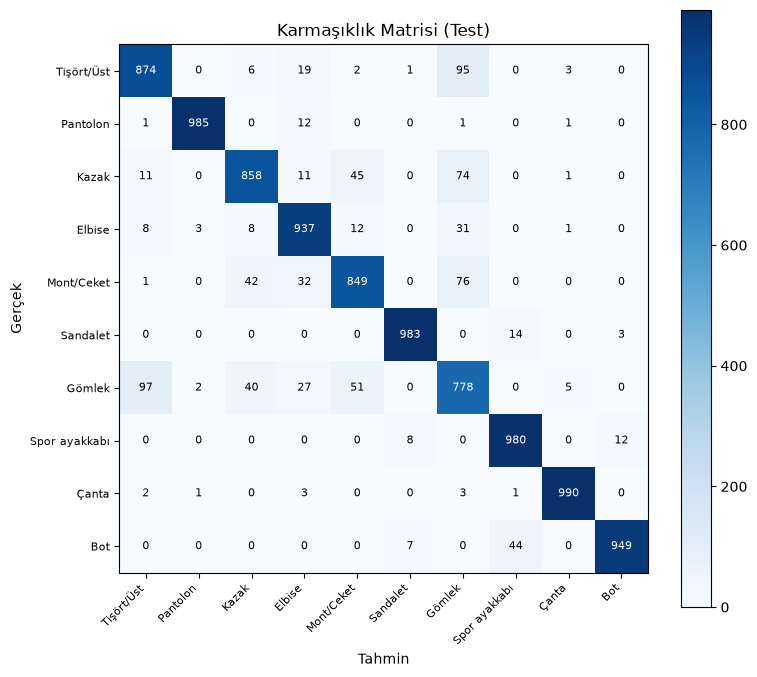

In [9]:
# Karmaşıklık matrisi
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, cmap="Blues")
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xticklabels(CLASSES, rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(CLASSES, fontsize=8)
ax.set_xlabel("Tahmin"); ax.set_ylabel("Gerçek")
ax.set_title("Karmaşıklık Matrisi (Test)")
plt.colorbar(im)
plt.tight_layout()
plt.savefig("outputs/karmasiklik_matrisi.png", dpi=150)
plt.show()

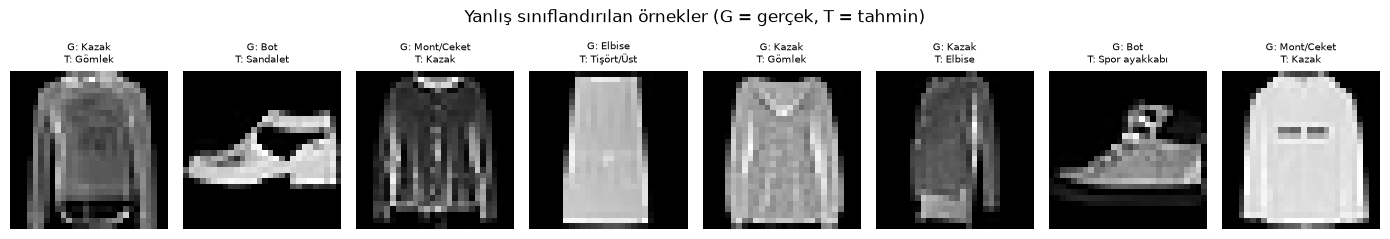

In [10]:
# Yanlış tahmin edilen bazı test örnekleri
wrong = np.where(y_pred != y_true)[0][:8]
fig, axes = plt.subplots(1, len(wrong), figsize=(14, 2.6))
for a, i in zip(axes, wrong):
    a.imshow(test_set.data[i], cmap="gray"); a.axis("off")
    a.set_title(f"G: {CLASSES[y_true[i]]}\nT: {CLASSES[y_pred[i]]}", fontsize=7)
plt.suptitle("Yanlış sınıflandırılan örnekler (G = gerçek, T = tahmin)")
plt.tight_layout()
plt.savefig("outputs/hatali_ornekler.png", dpi=150)
plt.show()

In [11]:
# Tahmin (inference) süresi
def sync():
    if device.type == "cuda": torch.cuda.synchronize()
    if device.type == "mps": torch.mps.synchronize()

x1 = test_set[0][0].unsqueeze(0).to(device)
with torch.no_grad():
    for _ in range(10):            # ısınma
        model(x1)
    sync()
    times = []
    for _ in range(200):
        t0 = time.perf_counter(); model(x1); sync(); times.append(time.perf_counter() - t0)

    xb = torch.stack([test_set[i][0] for i in range(1000)]).to(device)
    t0 = time.perf_counter(); model(xb); sync(); batch_time = time.perf_counter() - t0

infer_ms = np.mean(times) * 1000
print(f"Tek görüntü tahmin süresi: {infer_ms:.3f} ms (± {np.std(times)*1000:.3f})")
print(f"Toplu tahmin (1000 görüntü): {batch_time/1000*1000:.4f} ms / görüntü")

Tek görüntü tahmin süresi: 0.922 ms (± 0.074)
Toplu tahmin (1000 görüntü): 0.0432 ms / görüntü


## 7. Telefon Fotoğraflarıyla Test

Kendi telefonumla, düz bir zemine serdiğim 5 ürünün fotoğrafını çektim: tişört, kot pantolon, kazak, spor ayakkabı ve çanta.
Fotoğraflar `gercek_fotograflar/` klasöründe, dosya adının başındaki sayı gerçek sınıfı gösteriyor (ör. `8_canta.jpg` → 8 = Çanta).

Fashion-MNIST görüntüleri siyah zemin üzerinde açık renkli ve ortalanmış ürünlerden oluştuğu için fotoğrafları da bu formata çevirmem gerekti:
1. Zemin rengini fotoğrafın kenarlarından tahmin edip ürünü zeminden ayırma (renk farkı + Otsu eşikleme + GrabCut)
2. Ürünü kırpma
3. Gri tona çevirip renkleri ters çevirme (zemin siyah olsun diye), ürünün kontrastını artırma
4. 28x28'e küçültüp ortalama

In [12]:
def preprocess_photo(bgr):
    """Telefon fotoğrafını Fashion-MNIST formatına (28x28, siyah zemin) çevirir."""
    if bgr.dtype == np.uint16:                       # 16-bit PNG ise 8-bit'e çevir
        bgr = (bgr >> 8).astype(np.uint8)
    if bgr.ndim == 2:
        bgr = cv2.cvtColor(bgr, cv2.COLOR_GRAY2BGR)
    if bgr.shape[2] == 4:
        bgr = cv2.cvtColor(bgr, cv2.COLOR_BGRA2BGR)

    # 1) küçült ve Lab renk uzayına çevir
    h, w = bgr.shape[:2]
    s = 600 / max(h, w)
    small = cv2.resize(bgr, (int(w * s), int(h * s)), interpolation=cv2.INTER_AREA)
    blur = cv2.GaussianBlur(small, (7, 7), 0)
    lab = cv2.cvtColor(blur, cv2.COLOR_BGR2LAB).astype(np.float32)

    # 2) zemin rengi = kenar piksellerinin medyanı, her pikselin zemine uzaklığı
    H, W = lab.shape[:2]
    b = max(4, int(0.04 * min(H, W)))
    border = np.concatenate([lab[:b].reshape(-1, 3), lab[-b:].reshape(-1, 3),
                             lab[:, :b].reshape(-1, 3), lab[:, -b:].reshape(-1, 3)])
    diff = lab - np.median(border, axis=0)
    dist = np.sqrt(diff[..., 0]**2 + 4 * diff[..., 1]**2 + 4 * diff[..., 2]**2)
    dist = cv2.GaussianBlur(dist, (9, 9), 0)
    d8 = np.clip(dist / dist.max() * 255, 0, 255).astype(np.uint8)
    _, mask = cv2.threshold(d8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # GrabCut ile maskeyi iyileştir
    gc = np.where(mask > 0, cv2.GC_PR_FGD, cv2.GC_PR_BGD).astype(np.uint8)
    gc[:b] = gc[-b:] = cv2.GC_BGD
    gc[:, :b] = gc[:, -b:] = cv2.GC_BGD
    cv2.setRNGSeed(42)                               # GrabCut her seferinde aynı sonucu versin
    cv2.grabCut(blur, gc, None, np.zeros((1, 65)), np.zeros((1, 65)), 5, cv2.GC_INIT_WITH_MASK)
    mask = np.where((gc == cv2.GC_FGD) | (gc == cv2.GC_PR_FGD), 255, 0).astype(np.uint8)
    k = np.ones((5, 5), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, k, iterations=2)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, k)

    # en büyük parça(lar)ı tut, içini doldur
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask)
    areas = stats[1:, cv2.CC_STAT_AREA]
    keep = [i + 1 for i, a in enumerate(areas) if a >= 0.15 * areas.max()]
    mask = np.isin(labels, keep).astype(np.uint8) * 255
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    mask = np.zeros_like(mask)
    cv2.drawContours(mask, cnts, -1, 255, cv2.FILLED)

    # 3) gri ton, ters çevirme, zemin = 0, ürün kontrastını 80-255 aralığına ger
    gray = cv2.cvtColor(small, cv2.COLOR_BGR2GRAY)
    inv = (255 - gray).astype(np.float32)
    m = mask > 0
    lo, hi = np.percentile(inv[m], [2, 98])
    item = np.clip((inv - lo) / max(hi - lo, 1) * 175 + 80, 0, 255)
    item[~m] = 0

    # 4) kırp, uzun kenar 28 piksel olacak şekilde küçült, ortala
    ys, xs = np.nonzero(mask)
    crop = item[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    sc = 28 / max(crop.shape)
    nh, nw = max(1, round(crop.shape[0] * sc)), max(1, round(crop.shape[1] * sc))
    crop = cv2.resize(crop, (nw, nh), interpolation=cv2.INTER_AREA)
    out = np.zeros((28, 28), np.float32)
    oy, ox = (28 - nh) // 2, (28 - nw) // 2
    out[oy:oy + nh, ox:ox + nw] = crop
    return out.astype(np.uint8), small, mask

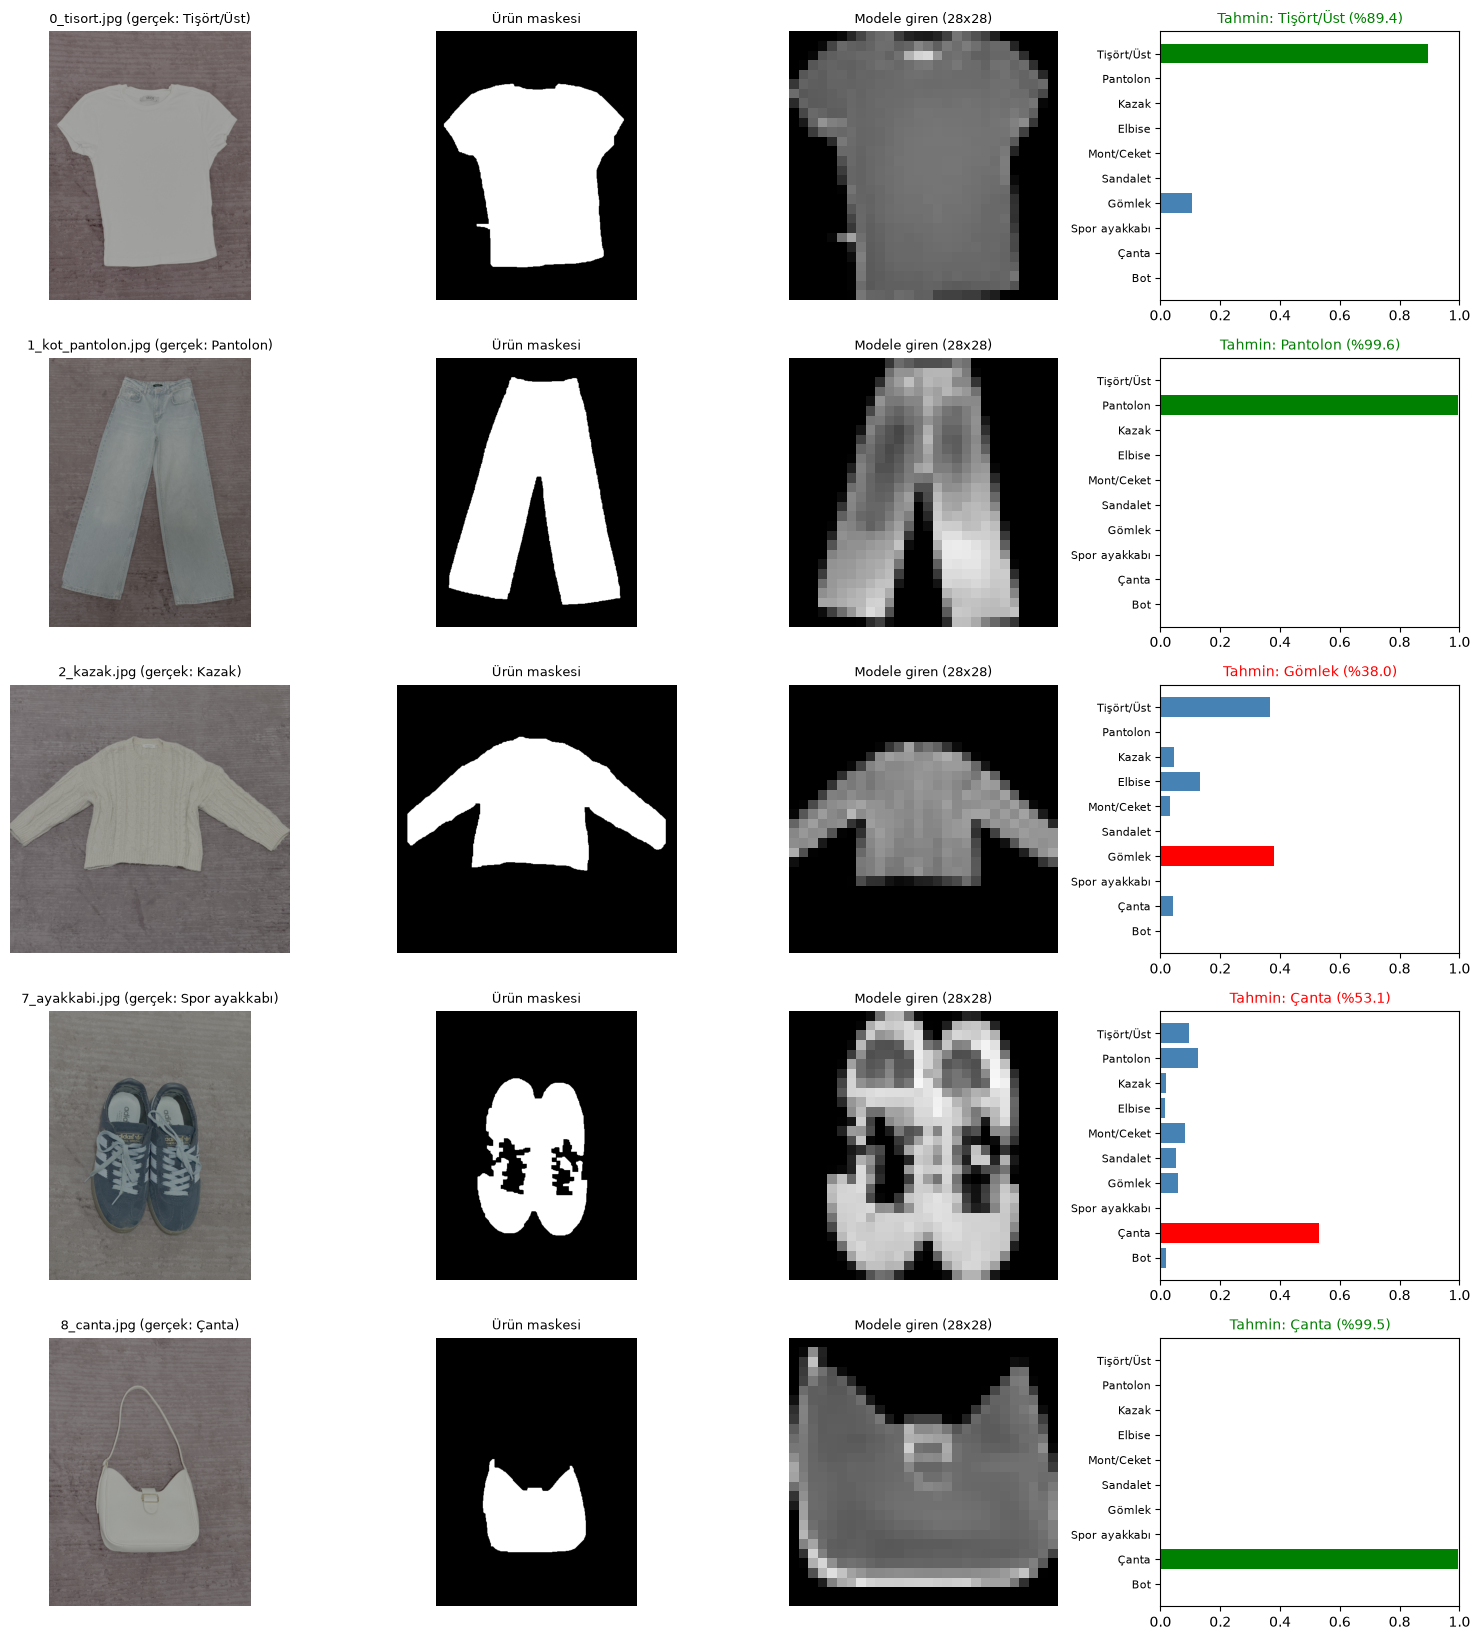

0_tisort.jpg           gerçek: Tişört/Üst     tahmin: Tişört/Üst     güven: % 89.4  DOĞRU
1_kot_pantolon.jpg     gerçek: Pantolon       tahmin: Pantolon       güven: % 99.6  DOĞRU
2_kazak.jpg            gerçek: Kazak          tahmin: Gömlek         güven: % 38.0  YANLIŞ
7_ayakkabi.jpg         gerçek: Spor ayakkabı  tahmin: Çanta          güven: % 53.1  YANLIŞ
8_canta.jpg            gerçek: Çanta          tahmin: Çanta          güven: % 99.5  DOĞRU

Telefon fotoğraflarında doğruluk: 3/5


In [13]:
files = sorted(glob.glob("gercek_fotograflar/*.jpg") + glob.glob("gercek_fotograflar/*.png"))
results = []
fig, axes = plt.subplots(len(files), 4, figsize=(15, 3.3 * len(files)))

for r, f in enumerate(files):
    name = os.path.basename(f)
    true = int(name.split("_")[0])
    img = cv2.imread(f, cv2.IMREAD_UNCHANGED)

    t0 = time.perf_counter()
    x28, small, mask = preprocess_photo(img)
    pre_time = time.perf_counter() - t0

    x = torch.tensor(x28 / 255.0, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)
    with torch.no_grad():
        probs = F.softmax(model(x), dim=1)[0].cpu().numpy()
    pred = int(probs.argmax())

    results.append({"dosya": name, "gercek": CLASSES[true], "tahmin": CLASSES[pred],
                    "guven": round(float(probs[pred]), 4),
                    "gercek_sinif_olasiligi": round(float(probs[true]), 4),
                    "dogru_mu": pred == true, "on_isleme_sn": round(pre_time, 2)})

    axes[r, 0].imshow(cv2.cvtColor(small, cv2.COLOR_BGR2RGB)); axes[r, 0].set_title(f"{name} (gerçek: {CLASSES[true]})", fontsize=9)
    axes[r, 1].imshow(mask, cmap="gray"); axes[r, 1].set_title("Ürün maskesi", fontsize=9)
    axes[r, 2].imshow(x28, cmap="gray", vmin=0, vmax=255); axes[r, 2].set_title("Modele giren (28x28)", fontsize=9)
    color = "green" if pred == true else "red"
    axes[r, 3].barh(range(10), probs, color=[color if i == pred else "steelblue" for i in range(10)])
    axes[r, 3].set_yticks(range(10)); axes[r, 3].set_yticklabels(CLASSES, fontsize=8)
    axes[r, 3].invert_yaxis(); axes[r, 3].set_xlim(0, 1)
    axes[r, 3].set_title(f"Tahmin: {CLASSES[pred]} (%{probs[pred]*100:.1f})", color=color, fontsize=10)
    for k in range(3):
        axes[r, k].axis("off")

plt.tight_layout()
plt.savefig("outputs/gercek_test_sonuclari.png", dpi=110)
plt.show()

for res in results:
    print(f"{res['dosya']:22s} gerçek: {res['gercek']:14s} tahmin: {res['tahmin']:14s} "
          f"güven: %{res['guven']*100:5.1f}  {'DOĞRU' if res['dogru_mu'] else 'YANLIŞ'}")
print(f"\nTelefon fotoğraflarında doğruluk: {sum(r['dogru_mu'] for r in results)}/{len(results)}")

In [14]:
# Bütün sonuçları rapor için kaydet
metrics = {
    "test_accuracy": acc, "test_precision_macro": prec, "test_recall_macro": rec, "test_f1_macro": f1,
    "best_val_acc": best_val_acc, "best_epoch": best_epoch, "epochs": EPOCHS,
    "training_time_sec": training_time, "inference_ms_single": infer_ms,
    "n_params": n_params, "device": str(device), "torch": torch.__version__,
    "python": platform.python_version(), "platform": platform.platform(),
    "per_class_report": classification_report(y_true, y_pred, target_names=CLASSES, digits=4, output_dict=True),
    "confusion_matrix": cm.tolist(),
    "real_photos": results,
}
with open("outputs/sonuclar.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)
print("outputs/sonuclar.json kaydedildi")

outputs/sonuclar.json kaydedildi


## Yorum

Model test kümesinde %91.83 doğruluğa ulaştı. En zor sınıf gömlek oldu (F1 0.756); tişört, kazak ve mont ile karışıyor. Telefon fotoğraflarında 3/5 doğru tahmin yapıldı. Pantolon (%99.6), çanta (%99.5) ve tişört (%89.4) doğru bulundu. Ayakkabı çanta olarak tahmin edildi, çünkü fotoğrafta iki ayakkabı vardı ve yukarıdan çekilmişti; veri setindeki ayakkabılar ise tek ve yandan çekilmiş. Kazak gömlek olarak tahmin edildi, çünkü kolları iki yana açık serilmişti. Bu sonuçlar, modelin eğitim verisinden farklı açı ve duruşlara karşı hassas olduğunu gösteriyor.